In [15]:
from src.parametric_estimation import ParametricEstimation
from src.data_generator import DataGenerator
from src.ampute_mar import AmputeMAR
import numpy as np

import matplotlib.pyplot as plt

from scipy.stats import logistic
from sklearn.metrics import root_mean_squared_error

from joblib import Parallel, delayed

In [16]:
# Specify data model
dg = DataGenerator(distr='Logistic')

In [17]:
# Single job
def job(
        n:int = None, # sample size
        d:int = None, # data dimension
        patterns = None, # arg of mice:ampute
        prop:float = None, # arg of mice::ampute
        eps: float = None, # clamping scale
        fast: bool = None, # if fast, use fast algorithm of nmm
        var_index:int = None, # which variable
        p:float = None, # quantile
        ):
    X = dg.sample_truth(n=n, d=d)
    M = AmputeMAR().ampute(X, patterns=patterns, prop=prop)[1]
    pe = ParametricEstimation(X=X, M=M)
    ps_gmm = pe._propensity_score_Xc(method='gmm', eps=eps)
    ps_nmm = pe._propensity_score_Xc(method='nmm', eps=eps, fast=fast)
    qs = (
        pe.quantile_by_ipw(var_index=var_index, p=p, propensity_score=ps_gmm).item(), 
        pe.quantile_by_ipw(var_index=var_index, p=p, propensity_score=ps_nmm).item(),
        pe.quantile_by_generation(var_index=var_index, p=p).item(),
    )
    ms = np.stack(
        [
            pe.mean_by_ipw(propensity_score=ps_gmm), 
            pe.mean_by_ipw(propensity_score=ps_nmm),
            pe.mean_by_generation(),
        ],
        axis=0
    )
    return qs, ms

In [ ]:
n = 2000
d = 3

n_pat = 10 # CHANGE to set the number of patterns
rng = np.random.default_rng(123)
patterns = AmputeMAR.sample_patterns(d, n, npattern=n_pat, rng=rng) 

prop = None
eps = 1e-3 # CHANGE to set the claming scale
fast = True
var_index = 0
p = 0.1

In [ ]:
B = 100 # CHANGE

results = Parallel(n_jobs=15)(
    delayed(job)(
        n=n,
        d=d,
        patterns=patterns,
        prop=prop,
        eps=eps,
        fast=fast,
        var_index=var_index,
        p=p,
        ) 
    for _ in range(B)
)

In [20]:
quantile_results = np.stack([q for q, _ in results])

mean_results = np.stack([
    np.sqrt(np.mean(np.square(m), axis=-1))
    for _, m in results
])

results = (quantile_results, mean_results)

# np.save('results/quantile_results.npy', quantile_results)
# np.save('results/mean_results.npy', mean_results)

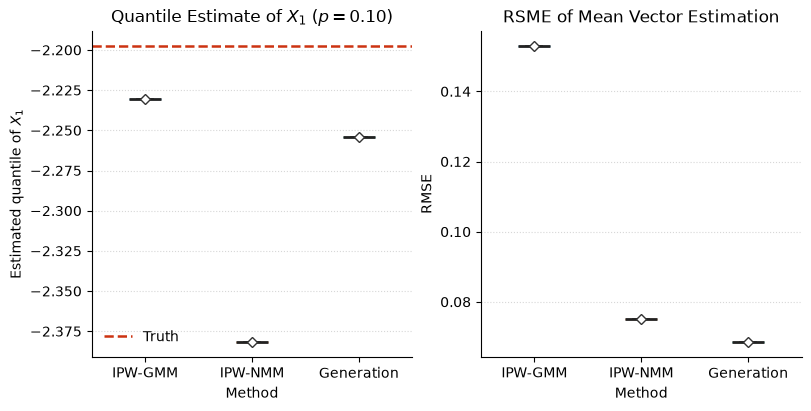

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)

for ax, result in zip(axes, results):

    bp = ax.boxplot(
        result,
        tick_labels=['IPW-GMM', 'IPW-NMM', 'Generation'],
        patch_artist=True,
        widths=0.3,
        showmeans=True,
        meanprops=dict(
            marker="D",
            markerfacecolor="white",
            markeredgecolor="#333333",
            markersize=5,
        ),
        medianprops=dict(color="#222222", linewidth=2),
        whiskerprops=dict(color="#555555", linewidth=1.2),
        capprops=dict(color="#555555", linewidth=1.2),
        flierprops=dict(
            marker="o",
            markersize=4,
            markerfacecolor="#999999",
            markeredgecolor="none",
            alpha=0.6,
        ),
    )

    # Colorblind-friendly palette
    colors = ["#0072B2", "#D55E00", "#009E73"]
    for box, color in zip(bp["boxes"], colors):
        box.set_facecolor(color)
        box.set_alpha(0.75)
        box.set_edgecolor(color)

    ax.yaxis.grid(True, linestyle=":", alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Reference quantile
y_ref = logistic.ppf(p)
axes[0].axhline(
    y=y_ref,
    color="#CC3311",
    linestyle="--",
    linewidth=1.8,
    label="Truth",
    zorder=0,
)

axes[0].set(
    title=fr"Quantile Estimate of $X_1$ ($p={p:.2f}$)",
    xlabel="Method",
    ylabel=r"Estimated quantile of $X_1$",
)

axes[1].set(
    title=fr"RSME of Mean Vector Estimation",
    xlabel="Method",
    ylabel=r"RMSE",
)

axes[0].legend(frameon=False, loc="best")

plt.savefig(f'results/pe_quantile_mean_{n_pat}_patterns_{B}_B.png',dpi=300,
    bbox_inches="tight",)

plt.show()


Reference: K. V. Mardia (1970), Measures of Multivariate Skewness and Kurtosis with Applications, Biometrika, 57(3), 519–530. https://doi.org/10.1093/biomet/57.3.519

In [22]:

# import torch


# def mardia_skewness(X: torch.Tensor, ridge: float = 0.0) -> torch.Tensor:
#     """
#     Estimate Mardia's multivariate skewness.

#     Args:
#         X: Tensor of shape (n_samples, n_features).
#         ridge: Optional diagonal regularization for covariance.

#     Returns:
#         Scalar tensor: estimated multivariate skewness.
#     """
#     n, p = X.shape

#     # Center the data
#     Xc = X - X.mean(dim=0, keepdim=True)

#     # Maximum-likelihood-style sample covariance (denominator n)
#     cov = (Xc.T @ Xc) / n

#     # Optional regularization
#     if ridge > 0:
#         cov = cov + ridge * torch.eye(
#             p, dtype=X.dtype, device=X.device
#         )

#     # Compute S^{-1} Xc^T without explicitly inverting S
#     solved = torch.linalg.solve(cov, Xc.T)

#     # Pairwise Mahalanobis inner products
#     A = Xc @ solved

#     # Mardia's multivariate skewness
#     return A.pow(3).mean()



# torch.manual_seed(42)

# X = torch.randn(500, 3, dtype=torch.float64)

# beta = mardia_skewness(X)

# print("Mardia skewness:", beta.item())

In [23]:
# dg = DataGenerator(distr='Logistic')

In [24]:
# n = 2000
# d = 20
# B = 50

In [25]:
# means = torch.empty((B, d))
# quantiles_X2 = torch.empty(B)
# skewestimates = torch.empty(B)
# skewtruths = torch.empty(B)

# rng = np.random.default_rng(123)
# # Sample incomplete missingness patterns once (1 = observed, 0 = missing).
# patterns = AmputeMAR.sample_patterns(d, n, rng)   # once, outside the loop

# # print(patterns)

# for i in range(B):
#     pe = ParametricEstimation(data_generator=dg, n=n, d=d, patterns=patterns, k_range=(10,20))
#     # print((pe.M.sum(dim=1) == d).float().mean())
#     means[i] = pe.mean()
#     quantiles_X2[i] = pe.quantile(var_index=1, p=0.2).item()
#     skewestimates[i] = pe.estimate(mardia_skewness)
#     skewtruths[i] = pe.get_truth(mardia_skewness)

In [26]:
# plt.boxplot(skewestimates, tick_labels=['Estimates'])
# plt.axhline(y=0, color='red', linestyle='--', label=f'truth = 0')
# plt.title('Mardia Skewness')
# plt.legend()
# plt.show()

In [27]:
# print('Mean estimates per batch: \n', means)

In [28]:
# #print('Quantile 0.2 estimates of X2 per batch: \n', quantiles_X2)

# q = quantiles_X2.detach().cpu().numpy()

# fig, ax = plt.subplots(figsize=(4, 5))
# ax.boxplot(q, widths=0.5, showmeans=True)
# ax.scatter(np.ones_like(q), q, alpha=0.4, color="k", zorder=3)  # individual estimates

# # optional: true value, if you know it
# # ax.axhline(true_q, color="red", linestyle="--", label="True 0.2-quantile")
# # ax.legend()

# ax.set_xticks([1])
# ax.set_xticklabels(["X2"])
# ax.set_ylabel("Estimated 0.2-quantile")
# ax.set_title(f"Quantile 0.2 estimates of X2 (B = {len(q)})")
# ax.axhline(y=logistic.ppf(0.2), color='red', linestyle='--', label=f'truth = {round(logistic.ppf(0.2),3)}')
# ax.legend()
# plt.tight_layout()
# plt.show()

## Mardia Skewness of a Gaussian-Copula Multivariate Logistic Distribution

### 1. Model definition

Let
$$
\mathbf Z=(Z_1,\ldots,Z_p)^\top
\sim N_p(\mathbf 0,\mathbf R),
$$
where \(\mathbf R\) is an AR(1) correlation matrix with entries
$$
R_{ij}=\rho^{|i-j|}, \qquad |\rho|<1, \qquad i,j \le p-1; \qquad R_{ip} = R_{pj} = 1
$$

Define the uniform random variables
$$
U_i=\Phi(Z_i), \qquad i=1,\ldots,p,
$$
where $\Phi$ denotes the standard normal cumulative distribution function.

Transform the components to standard logistic marginals:
$$
X_i=F_L^{-1}(U_i),
$$
where
$$
F_L(x)=\frac{1}{1+e^{-x}}
$$
is the standard logistic cumulative distribution function. Since
$$
F_L^{-1}(u)=\log\left(\frac{u}{1-u}\right),
$$
we obtain
$$
X_i=\log\left(
\frac{\Phi(Z_i)}{1-\Phi(Z_i)}
\right).
$$

Consequently, each $X_i$ follows a standard logistic distribution, while the dependence structure is induced by the Gaussian copula.

### 2. Central symmetry

The multivariate Gaussian distribution is centrally symmetric:
$$
\mathbf Z\overset{d}{=}-\mathbf Z.
$$

Moreover, the standard normal cumulative distribution function satisfies
$$
\Phi(-z)=1-\Phi(z).
$$

Therefore,
$$
\begin{aligned}
X_i(-Z_i)
&=\log\left(
\frac{\Phi(-Z_i)}{1-\Phi(-Z_i)}
\right)\\
&=\log\left(
\frac{1-\Phi(Z_i)}{\Phi(Z_i)}
\right)\\
&=-\log\left(
\frac{\Phi(Z_i)}{1-\Phi(Z_i)}
\right)\\
&=-X_i(Z_i).
\end{aligned}
$$

Thus, writing $\mathbf X=T(\mathbf Z)$ for the componentwise transformation,
$$
T(-\mathbf Z)=-T(\mathbf Z).
$$

It follows that
$$
\boxed{\mathbf X\overset{d}{=}-\mathbf X.}
$$

Hence, the multivariate logistic vector is centrally symmetric about the origin. Since its marginal means are zero and its second moments are finite,
$$
\boldsymbol\mu=E[\mathbf X]=\mathbf 0.
$$

### 3. Definition of Mardia's multivariate skewness

Let $\boldsymbol\Sigma=\operatorname{Cov}(\mathbf X)$, assumed positive definite, and let $\mathbf X$ and $\mathbf Y$ be independent and identically distributed copies.

$$
E\left[
\left\{
(\mathbf X-\boldsymbol\mu)^\top
\boldsymbol\Sigma^{-1}
(\mathbf Y-\boldsymbol\mu)
\right\}^{3}
\right].
$$

$$
E\left[
\left(
\mathbf X^\top\boldsymbol\Sigma^{-1}\mathbf Y
\right)^3
\right].
$$

### 4. Proof that Mardia's skewness is zero

$$
\left(
\mathbf x^\top\boldsymbol\Sigma^{-1}\mathbf y
\right)^3.
$$

Because $\mathbf X$ and $\mathbf Y$ are independent and centrally symmetric,
$$
\mathbf Y\overset{d}{=}-\mathbf Y.
$$

Consequently,
$$
\begin{aligned}
\beta_{1,p}
&=E\left[
\left(
\mathbf X^\top\boldsymbol\Sigma^{-1}\mathbf Y
\right)^3
\right]\
&=E\left[
\left(
\mathbf X^\top\boldsymbol\Sigma^{-1}(-\mathbf Y)
\right)^3
\right]\
&=-E\left[
\left(
\mathbf X^\top\boldsymbol\Sigma^{-1}\mathbf Y
\right)^3
\right]\
&=-\beta_{1,p}.
\end{aligned}
$$

Therefore,
$$
2\beta_{1,p}=0,
$$
which implies
$$
\boxed{\beta_{1,p}=0.}
$$